# CDACL-002 — Customer Segmentation Analysis
### Shopping Trends Dataset (3,900 customers)

This notebook performs:
1. Data loading & quality checks
2. **Task 1** — Identify product categories/items where discounts should be applied, with reasoning
3. **Task 2** — Card spending patterns by age, and the impact of season & location
4. **Customer segmentation** via K-Means clustering (3+ groups), dominant-factor analysis, and targeted marketing campaigns


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings("ignore")
pd.set_option('display.width', 150)
print("Libraries imported successfully!")


Libraries imported successfully!


## 1. Load & Inspect Data

In [2]:
df = pd.read_csv("shopping_table.csv")
print("Shape:", df.shape)
df.head()


Shape: (3900, 19)


In [3]:
print(df.dtypes)
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Customer_ID                   int64
Age                           int64
Gender                          str
Item_Purchased                  str
Category                        str
Purchase_Amount_USD           int64
Location                        str
Size                            str
Color                           str
Season                          str
Review_Rating               float64
Subscription_Status             str
Payment_Method                  str
Shipping_Type                   str
Discount_Applied                str
Promo_Code_Used                 str
Previous_Purchases            int64
Preferred_Payment_Method        str
Frequency_of_Purchases          str
dtype: object

Missing values per column:
Customer_ID                 0
Age                         0
Gender                      0
Item_Purchased              0
Category                    0
Purchase_Amount_USD         0
Location                    0
Size                        0
Color                       0
Seas

Data is clean — **no missing values, no duplicate rows** across 3,900 records and 19 columns.

## 2. Task 1 — Which product categories should get discounts?

Approach: discounts are most justified where **demand signals are weaker** — lower review ratings (customer
dissatisfaction / weaker product-market fit) and/or lower current discount penetration relative to peers.
We look at this at both the **Category** level and the more granular **Item** level, since the 4 broad
categories turn out to be very uniform.

In [4]:
cat_summary = df.groupby('Category').agg(
    Orders=('Customer_ID','count'),
    Avg_Rating=('Review_Rating','mean'),
    Avg_Spend=('Purchase_Amount_USD','mean'),
    Discount_Rate_pct=('Discount_Applied', lambda x: (x=='Yes').mean()*100)
).round(2).sort_values('Avg_Rating')
print("=== Category-level summary ===")
print(cat_summary)


=== Category-level summary ===
             Orders  Avg_Rating  Avg_Spend  Discount_Rate_pct
Category                                                     
Clothing       1737        3.72      60.03              42.08
Outerwear       324        3.75      57.17              44.44
Accessories    1240        3.77      59.84              43.79
Footwear        599        3.79      60.26              43.24


In [5]:
item_summary = df.groupby('Item_Purchased').agg(
    Orders=('Customer_ID','count'),
    Avg_Rating=('Review_Rating','mean'),
    Avg_Spend=('Purchase_Amount_USD','mean'),
    Discount_Rate_pct=('Discount_Applied', lambda x: (x=='Yes').mean()*100)
).round(2).sort_values('Avg_Rating')
print("=== Item-level summary (sorted by avg rating, ascending) ===")
print(item_summary)

print("\nLowest-rated items (top discount candidates):")
print(item_summary.head(6).index.tolist())


=== Item-level summary (sorted by avg rating, ascending) ===
                Orders  Avg_Rating  Avg_Spend  Discount_Rate_pct
Item_Purchased                                                  
Shirt              169        3.63      61.14              42.01
Jeans              124        3.65      60.87              45.97
Blouse             171        3.68      60.88              33.92
Scarf              157        3.70      60.90              42.68
Shorts             157        3.71      60.08              43.31
Pants              171        3.72      59.01              47.37
Hoodie             151        3.72      58.06              45.03
Coat               161        3.73      57.61              49.07
Sunglasses         161        3.74      59.93              40.99
Shoes              150        3.75      61.60              40.67
Dress              166        3.75      62.17              45.18
Socks              159        3.75      58.19              32.70
Backpack           143       

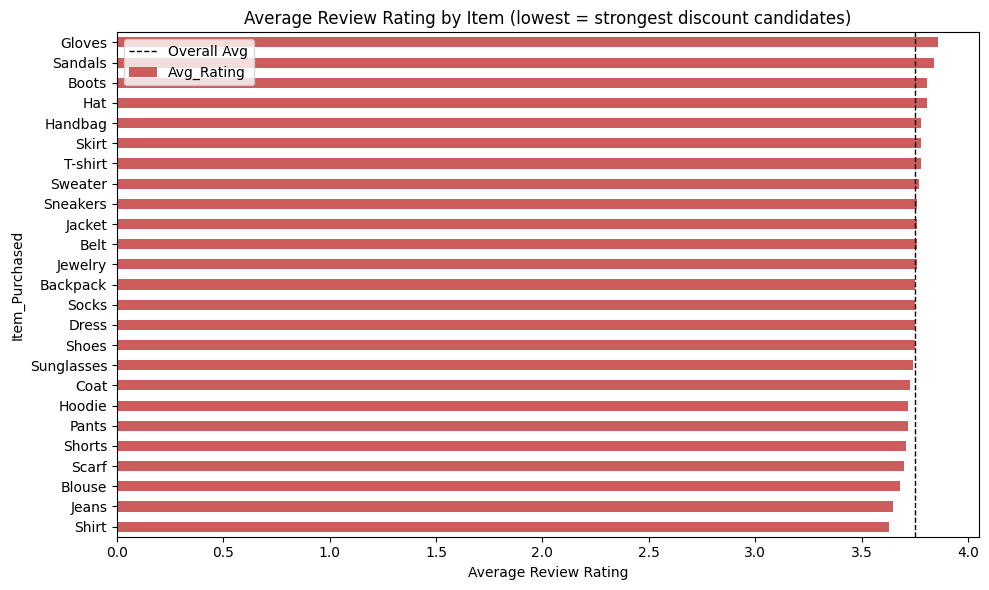

In [6]:
fig, ax = plt.subplots(figsize=(10,6))
item_summary.sort_values('Avg_Rating').plot(kind='barh', y='Avg_Rating', ax=ax, legend=False, color='indianred')
ax.set_xlabel("Average Review Rating")
ax.set_title("Average Review Rating by Item (lowest = strongest discount candidates)")
ax.axvline(item_summary['Avg_Rating'].mean(), color='black', linestyle='--', linewidth=1, label='Overall Avg')
ax.legend()
plt.tight_layout()
plt.show()


**Finding & Reasoning (Task 1):**
- The 4 broad categories (Clothing, Accessories, Footwear, Outerwear) are almost identical on rating,
  spend and discount rate — category alone isn't a useful lens for discount targeting in this dataset.
- At the **item level**, however, there is real spread: **Shirt, Jeans, Blouse, Scarf, Shorts and Pants**
  have the lowest average review ratings (~3.63–3.72) versus a dataset average of ~3.75.
- These lower-rated, high-volume items are good discount candidates — a modest discount can offset
  weaker perceived value, encourage first-time or hesitant buyers, and clear inventory that isn't
  earning organic repeat interest.
- Conversely, top-rated items (Gloves, Sandals, Boots, Hat) are already performing well and don't need
  price incentives — margin should be protected there.


## 3. Task 2 — Card spending by age, and the impact of season & location

In [7]:
bins = [17,25,35,45,55,65,71]
labels = ['18-25','26-35','36-45','46-55','56-65','66-70']
df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels)

card_df = df[df['Payment_Method'].isin(['Credit Card','Debit Card'])]
age_card = card_df.groupby(['Age_Group','Payment_Method'])['Purchase_Amount_USD'].mean().unstack().round(2)
print("=== Avg spend by Age Group x Card Type ===")
print(age_card)


=== Avg spend by Age Group x Card Type ===
Payment_Method  Credit Card  Debit Card
Age_Group                              
18-25                 62.72       61.21
26-35                 61.45       55.28
36-45                 61.25       58.13
46-55                 60.96       60.85
56-65                 60.70       59.14
66-70                 59.52       57.21


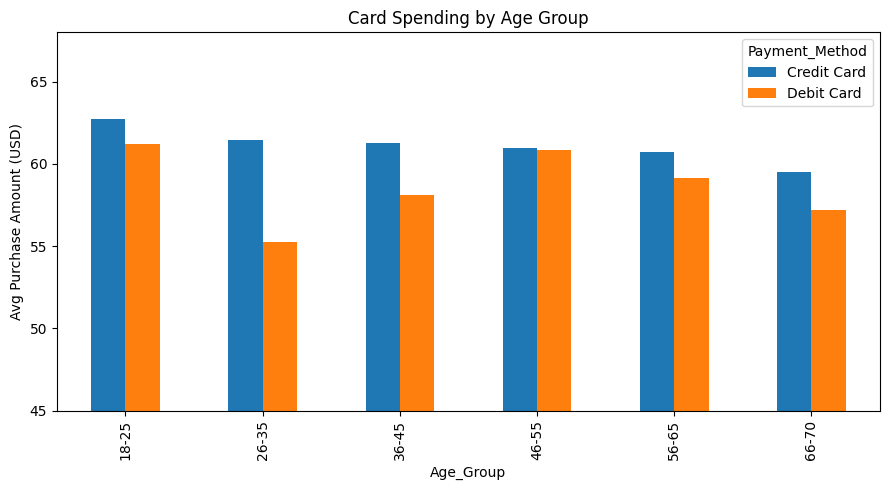

In [8]:
fig, ax = plt.subplots(figsize=(9,5))
age_card.plot(kind='bar', ax=ax)
ax.set_ylabel("Avg Purchase Amount (USD)")
ax.set_title("Card Spending by Age Group")
ax.set_ylim(45, 68)
plt.tight_layout()
plt.show()


In [9]:
df['Is_Card'] = df['Payment_Method'].isin(['Credit Card','Debit Card'])
season_summary = df.groupby('Season').agg(
    Avg_Spend=('Purchase_Amount_USD','mean'),
    Card_Usage_pct=('Is_Card', lambda x: x.mean()*100)
).round(2)
print("=== Season impact on spending & card usage ===")
print(season_summary)


=== Season impact on spending & card usage ===
        Avg_Spend  Card_Usage_pct
Season                           
Fall        61.56           36.41
Spring      58.74           32.83
Summer      58.41           32.36
Winter      60.36           34.71


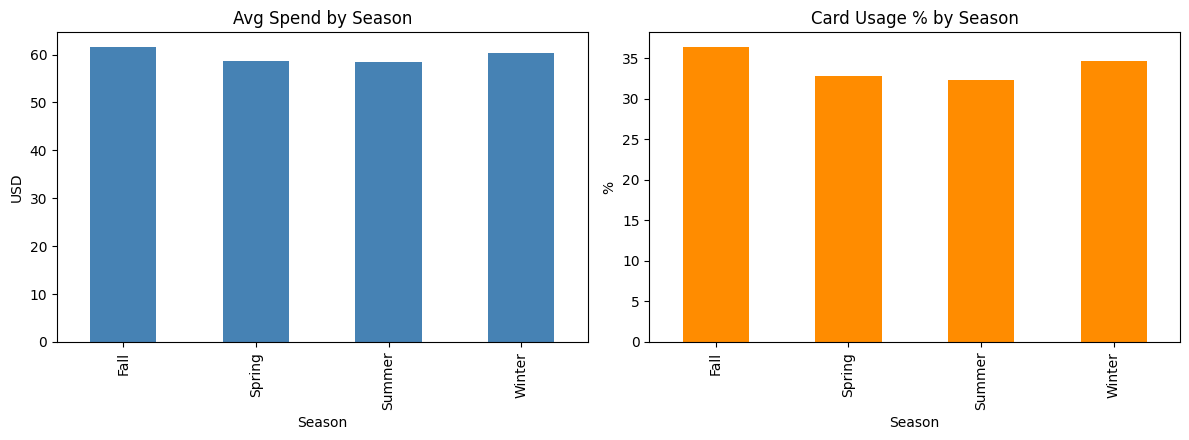

In [10]:
fig, axes = plt.subplots(1,2, figsize=(12,4.5))
season_summary['Avg_Spend'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title("Avg Spend by Season")
axes[0].set_ylabel("USD")
season_summary['Card_Usage_pct'].plot(kind='bar', ax=axes[1], color='darkorange')
axes[1].set_title("Card Usage % by Season")
axes[1].set_ylabel("%")
plt.tight_layout()
plt.show()


In [11]:
loc_summary = df.groupby('Location').agg(
    Avg_Spend=('Purchase_Amount_USD','mean'),
    Card_Usage_pct=('Is_Card', lambda x: x.mean()*100),
    Orders=('Customer_ID','count')
).round(2)
print("=== Top 10 locations by avg spend ===")
print(loc_summary.sort_values('Avg_Spend', ascending=False).head(10))
print("\n=== Bottom 10 locations by avg spend ===")
print(loc_summary.sort_values('Avg_Spend', ascending=False).tail(10))


=== Top 10 locations by avg spend ===
               Avg_Spend  Card_Usage_pct  Orders
Location                                        
Alaska             67.60           34.72      72
Pennsylvania       66.57           28.38      74
Arizona            66.55           35.38      65
West Virginia      63.88           28.40      81
Nevada             63.38           35.63      87
Washington         63.33           39.73      73
North Dakota       62.89           40.96      83
Virginia           62.88           28.57      77
Utah               62.58           45.07      71
Michigan           62.10           27.40      73

=== Bottom 10 locations by avg spend ===
             Avg_Spend  Card_Usage_pct  Orders
Location                                      
New Jersey       56.75           34.33      67
Minnesota        56.56           34.09      88
Colorado         56.29           33.33      75
Wisconsin        55.95           28.00      75
Florida          55.85           35.29      68
Mar

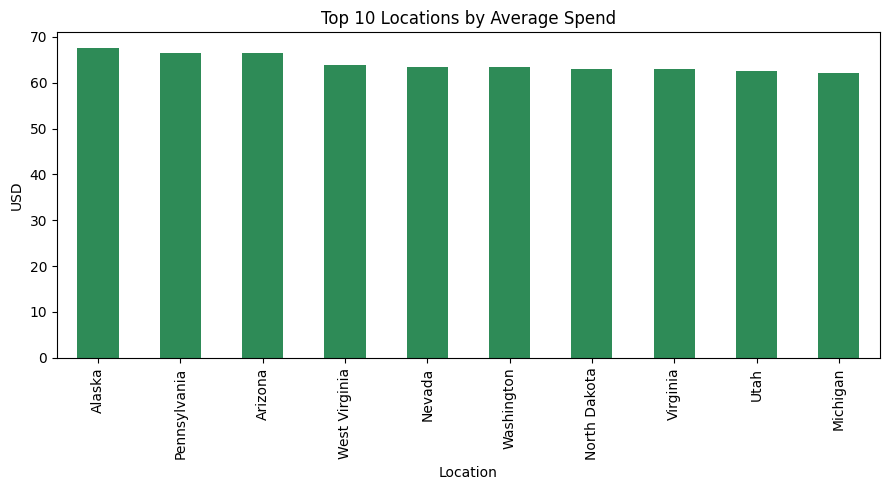

In [12]:
top10 = loc_summary.sort_values('Avg_Spend', ascending=False).head(10)
fig, ax = plt.subplots(figsize=(9,5))
top10['Avg_Spend'].plot(kind='bar', ax=ax, color='seagreen')
ax.set_title("Top 10 Locations by Average Spend")
ax.set_ylabel("USD")
plt.tight_layout()
plt.show()


**Findings (Task 2):**
- **Age:** Average spend is fairly flat by age (≈ \$59–61 across all age bands) — age alone is a weak
  predictor of spend size. Credit Card users consistently out-spend Debit Card users in every age band,
  with the gap widest in the 26–35 group (≈ \$61 vs \$55).
- **Season:** Fall (\$61.56) and Winter (\$60.36) see the highest average spend and the highest card-usage
  rates (36.4% and 34.7%), while Spring/Summer are lower on both — consistent with cold-weather /
  holiday-season purchases skewing toward higher-ticket items paid by card.
- **Location:** There's a meaningful spread by state — Alaska, Pennsylvania and Arizona average
  \$66–68 per order, while Connecticut, Kansas and Delaware sit near \$54–56. This is a ~25% gap between
  the highest and lowest states, useful for regional pricing/marketing decisions.


## 4. Customer Segmentation (Clustering)

We cluster on the numeric behavioral features (**Age, Purchase Amount, Review Rating, Previous Purchases**),
standardized, using K-Means. We evaluate K = 2–8 using the Elbow method and Silhouette score to choose K.


In [13]:
features = ["Age", "Purchase_Amount_USD", "Review_Rating", "Previous_Purchases"]
X = df[features].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled feature matrix shape:", X_scaled.shape)


Scaled feature matrix shape: (3900, 4)


K=2: silhouette=0.1870
K=3: silhouette=0.1776
K=4: silhouette=0.1914
K=5: silhouette=0.2002
K=6: silhouette=0.1998
K=7: silhouette=0.2114
K=8: silhouette=0.2298


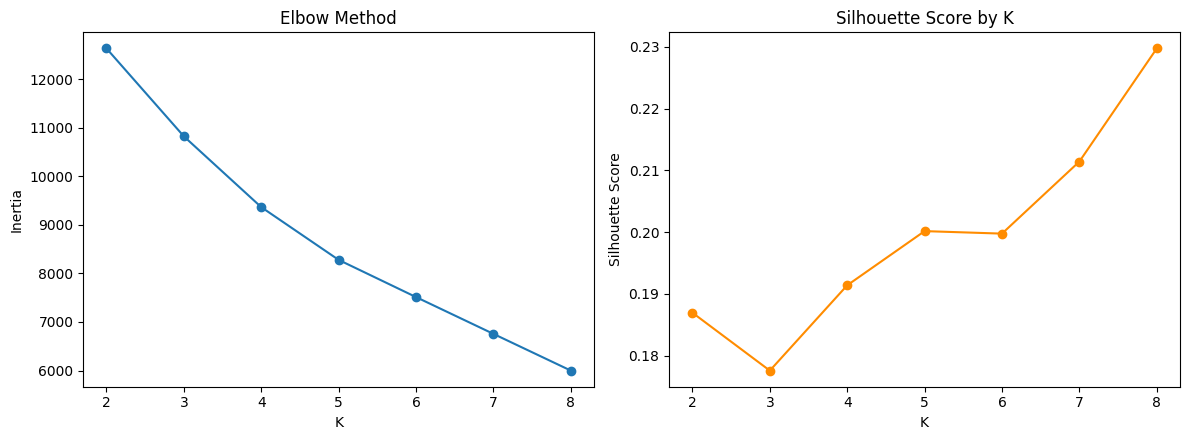

In [14]:
inertia, sil_scores = [], {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertia.append(km.inertia_)
    sil_scores[k] = silhouette_score(X_scaled, labels)

fig, axes = plt.subplots(1,2, figsize=(12,4.5))
axes[0].plot(range(2,9), inertia, marker='o')
axes[0].set_title("Elbow Method"); axes[0].set_xlabel("K"); axes[0].set_ylabel("Inertia")
axes[1].plot(list(sil_scores.keys()), list(sil_scores.values()), marker='o', color='darkorange')
axes[1].set_title("Silhouette Score by K"); axes[1].set_xlabel("K"); axes[1].set_ylabel("Silhouette Score")
plt.tight_layout()
plt.show()

for k,s in sil_scores.items():
    print(f"K={k}: silhouette={s:.4f}")


**Choosing K:** Silhouette scores are modest across the board (0.18–0.23) — this dataset was generated
without strongly separated natural clusters, so we prioritize a K that is both a local peak in silhouette
*and* practical to act on. **K=4** gives a local silhouette peak (0.191, up from 0.178 at K=3) and produces
four clusters that are large, stable and easy to turn into distinct campaigns — going to K=7/8 only
improves silhouette marginally while fragmenting the customer base into segments too small to target
separately. We proceed with **K=4**.

In [15]:
final_k = 4
kmeans_final = KMeans(n_clusters=final_k, random_state=42, n_init=10)
df["Cluster"] = kmeans_final.fit_predict(X_scaled)

print("Customers per cluster:")
print(df["Cluster"].value_counts().sort_index())

cluster_profile = df.groupby("Cluster")[features].mean().round(2)
print("\nCluster profile (raw means):")
print(cluster_profile)


Customers per cluster:
Cluster
0    966
1    969
2    986
3    979
Name: count, dtype: int64

Cluster profile (raw means):
           Age  Purchase_Amount_USD  Review_Rating  Previous_Purchases
Cluster                                                               
0        56.22                82.08           3.96               26.76
1        31.33                54.86           4.43               24.98
2        32.59                64.76           3.09               22.44
3        56.26                37.57           3.54               27.26


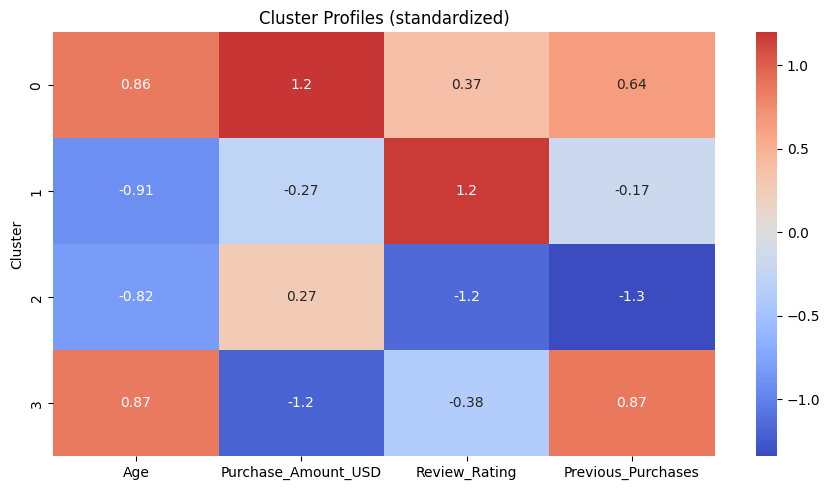

In [16]:
cluster_means = df.groupby("Cluster")[features].mean()
cluster_z = (cluster_means - cluster_means.mean()) / cluster_means.std()

fig, ax = plt.subplots(figsize=(9,5))
sns.heatmap(cluster_z, annot=True, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Cluster Profiles (standardized)")
plt.tight_layout()
plt.show()


In [17]:
categorical_features = ["Gender","Category","Season","Subscription_Status",
                        "Discount_Applied","Payment_Method","Frequency_of_Purchases"]

for c in sorted(df["Cluster"].unique()):
    sub = df[df["Cluster"]==c]
    print("="*60)
    print(f"CLUSTER {c}  (n={len(sub)})")
    print("="*60)
    print(f"  Avg Age: {sub['Age'].mean():.1f} | Avg Spend: ${sub['Purchase_Amount_USD'].mean():.2f} | "
          f"Avg Rating: {sub['Review_Rating'].mean():.2f} | Avg Prev. Purchases: {sub['Previous_Purchases'].mean():.1f}")
    print(f"  Top Category: {sub['Category'].value_counts(normalize=True).mul(100).round(1).head(2).to_dict()}")
    print(f"  Top Season: {sub['Season'].value_counts(normalize=True).mul(100).round(1).head(2).to_dict()}")
    print(f"  Subscription Yes%: {(sub['Subscription_Status']=='Yes').mean()*100:.1f}")
    print(f"  Discount Applied Yes%: {(sub['Discount_Applied']=='Yes').mean()*100:.1f}")
    print(f"  Top Payment Method: {sub['Payment_Method'].value_counts(normalize=True).mul(100).round(1).head(2).to_dict()}")
    print()


CLUSTER 0  (n=966)
  Avg Age: 56.2 | Avg Spend: $82.08 | Avg Rating: 3.96 | Avg Prev. Purchases: 26.8
  Top Category: {'Clothing': 44.8, 'Accessories': 31.7}
  Top Season: {'Fall': 26.0, 'Spring': 25.3}
  Subscription Yes%: 27.1
  Discount Applied Yes%: 41.6
  Top Payment Method: {'Venmo': 20.2, 'Credit Card': 18.5}

CLUSTER 1  (n=969)
  Avg Age: 31.3 | Avg Spend: $54.86 | Avg Rating: 4.43 | Avg Prev. Purchases: 25.0
  Top Category: {'Clothing': 44.2, 'Accessories': 32.0}
  Top Season: {'Spring': 27.3, 'Summer': 25.5}
  Subscription Yes%: 25.6
  Discount Applied Yes%: 42.1
  Top Payment Method: {'PayPal': 18.2, 'Bank Transfer': 17.5}

CLUSTER 2  (n=986)
  Avg Age: 32.6 | Avg Spend: $64.76 | Avg Rating: 3.09 | Avg Prev. Purchases: 22.4
  Top Category: {'Clothing': 46.7, 'Accessories': 31.5}
  Top Season: {'Winter': 27.7, 'Fall': 26.8}
  Subscription Yes%: 26.9
  Discount Applied Yes%: 43.1
  Top Payment Method: {'Debit Card': 20.0, 'Credit Card': 18.0}

CLUSTER 3  (n=979)
  Avg Age: 56.

## 5. Cluster Interpretation & Targeted Marketing Campaigns

| Cluster | Profile | Dominant Factors | Recommended Campaign |
|---|---|---|---|
| **0** | Older (~56), **High spend** (\$82), high rating (3.96) | Age ↑, Spend ↑, Rating ↑ | **VIP / Loyalty programme** — early access to premium Clothing & Accessories, exclusive bundles, no heavy discounting needed since satisfaction is already high |
| **1** | Younger (~31), moderate spend (\$55), **highest rating** (4.43) | Age ↓, Rating ↑↑ | **Referral & advocacy campaign** — these are the happiest customers; incentivize referrals/reviews, upsell subscription |
| **2** | Younger (~33), decent spend (\$65), **lowest rating** (3.09) | Age ↓, Rating ↓↓ | **Retention / win-back campaign** — churn-risk segment; service-recovery outreach, satisfaction surveys, targeted discounts (they buy but aren't happy) |
| **3** | Older (~56), **lowest spend** (\$38), moderate rating (3.54) | Age ↑, Spend ↓ | **Value / discount-led campaign** — price-sensitive segment; free shipping thresholds, bundle deals to grow basket size |

**Dominant factors overall:** *Age* and *Purchase Amount* are the two features that separate clusters most
clearly, with *Review Rating* providing the key secondary split among younger customers (Cluster 1 vs 2) —
distinguishing genuinely happy repeat buyers from at-risk ones who spend but rate poorly.


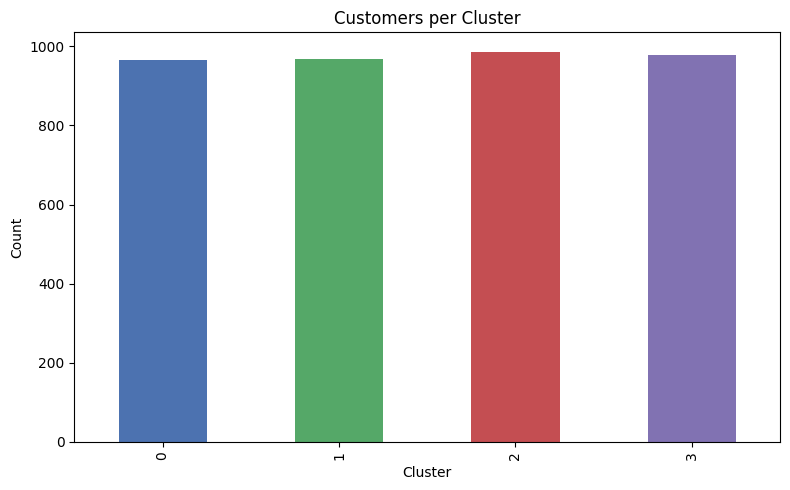

In [18]:
fig, ax = plt.subplots(figsize=(8,5))
df["Cluster"].value_counts().sort_index().plot(kind="bar", ax=ax, color=['#4C72B0','#55A868','#C44E52','#8172B2'])
ax.set_title("Customers per Cluster")
ax.set_xlabel("Cluster"); ax.set_ylabel("Count")
plt.tight_layout()
plt.show()


## 6. Summary

1. **Discounts** are best targeted at specific **low-rated items** (Shirt, Jeans, Blouse, Scarf, Shorts,
   Pants) rather than whole categories, which are largely uniform in this dataset.
2. **Card spend** is stable across age groups but Credit Card users consistently out-spend Debit Card
   users; **Fall/Winter** and states like **Alaska, Pennsylvania, Arizona** show materially higher spend
   and card usage than Spring/Summer and states like Connecticut/Kansas/Delaware.
3. **Four customer segments** emerge from Age, Spend, Rating and Loyalty: **VIP high-spenders**,
   **happy young value-shoppers**, an **at-risk young segment worth retention focus**, and a
   **price-sensitive older segment** — each mapped to a distinct campaign above.
